# Supervised Classification: Model Comparison, Tuning and Champion Selection

**Problem:** predict loan default (binary, ~19% positive) from the credit table built in the preprocessing notebook.

**Protocol**
1. Split first; the **test set is used once**, after the champion is chosen.
2. Every model sits behind the same leak-free preprocessing pipeline, so imputation, scaling, encodings and the correlation filter are re-fit inside each CV fold.
3. Four architectures (Logistic Regression, Random Forest, XGBoost, LightGBM) plus a majority-class dummy. Each is tuned with **Optuna (TPE) + stratified 5-fold CV**, optimising ROC-AUC.
4. Validation scores come from **fresh out-of-fold predictions** (different fold seed from the tuning folds, to limit selection bias). The decision threshold for precision/recall/F1 is chosen on those out-of-fold predictions, never on test.
5. Champion = best validation ROC-AUC. The test table is confirmation, not selection.

In [1]:
import warnings, json, time, platform; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, optuna
import sklearn, xgboost, lightgbm
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, precision_score,
                             recall_score, f1_score, confusion_matrix, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.utils.validation import check_is_fitted
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42; DATA_SOURCE = "synthetic"
pd.set_option("display.width", 140)

## 1. Data and split

In [2]:
def make_credit_default(n=8000, seed=SEED):
    """Seeded synthetic credit-default data with realistic pitfalls."""
    rng = np.random.default_rng(seed)
    z = lambda v: (v - v.mean()) / v.std()
    age = np.clip(rng.normal(41, 12, n), 21, 75).round()
    income = rng.lognormal(10.9, 0.55, n).round(-2)
    months_employed = np.clip(rng.gamma(2.2, 30, n), 0, 480).round()
    loan_amount = (income * rng.uniform(0.1, 0.9, n)).round(-2)
    dti = rng.uniform(0.05, 0.45, n)
    monthly_debt = (income / 12 * dti).round()
    credit_limit = (income * rng.uniform(0.2, 0.8, n)).round(-2)
    utilization = np.clip(rng.beta(2, 3, n), 0, 1)
    total_balance = (credit_limit * utilization).round()
    open_accounts = rng.poisson(5, n)
    late_12m = rng.poisson(0.3 + 1.5 * utilization)
    monthly_income = (income / 12).round()                        # redundant export field
    education = rng.choice(["High school", "Bachelor", "Master", "PhD"], n, p=[.35, .4, .2, .05])
    home = rng.choice(["Rent", "Mortgage", "Own", "Other"], n, p=[.4, .35, .2, .05])
    purpose = rng.choice(["Car", "Home improvement", "Debt consolidation", "Education", "Medical", "Business"], n)
    region = rng.choice(["North", "South", "East", "West", "Central"], n)
    ind_eff = rng.normal(0, 0.4, 40)
    industry_id = rng.integers(0, 40, n)                          # 40 levels, real signal
    postal = rng.integers(0, 500, n)                              # 500 levels, pure noise
    purpose_eff = dict(zip(np.unique(purpose), rng.normal(0, .25, 6)))
    logit = (-2.45 + 0.9*z(late_12m) + 1.0*z(dti) + 0.7*z(utilization)
             - 0.5*z(np.log(income)) - 0.3*z(np.log1p(months_employed))
             + 0.4*(home == "Rent") + np.array([purpose_eff[p] for p in purpose])
             + ind_eff[industry_id] + 0.2*z(loan_amount/income))
    default = (rng.random(n) < 1/(1+np.exp(-logit))).astype(int)
    # LEAK: recorded 30 days AFTER the outcome, so unavailable at decision time
    collections = np.where(default == 1,
                           np.where(rng.random(n) < .92, "in_collections", "none"),
                           np.where(rng.random(n) < .02, "in_collections", "none"))
    df = pd.DataFrame(dict(customer_id=[f"C{i:05d}" for i in range(n)], age=age, income=income,
        monthly_income=monthly_income, loan_amount=loan_amount, monthly_debt=monthly_debt,
        debt_to_income=dti.round(3), credit_limit=credit_limit, credit_utilization=utilization.round(3),
        total_balance=total_balance, open_accounts=open_accounts, late_payments_12m=late_12m,
        months_employed=months_employed, education=education, home_ownership=home,
        loan_purpose=purpose, region=region, industry=[f"IND_{i:02d}" for i in industry_id],
        postal_prefix=[f"PC_{i:03d}" for i in postal],
        collections_status_30d_after=collections, default=default))
    # missingness: random, plus informative (defaulters hide employment history more often)
    miss = lambda p: rng.random(n) < p
    m_inc = miss(0.08); df.loc[m_inc, ["income", "monthly_income"]] = np.nan
    df.loc[miss(0.06 + 0.12*default), "months_employed"] = np.nan
    df.loc[miss(0.05), "credit_utilization"] = np.nan
    df.loc[miss(0.06), "education"] = np.nan
    df.loc[miss(0.03), "home_ownership"] = np.nan
    return df

def load_data(source=DATA_SOURCE):
    if source == "synthetic":
        df = make_credit_default()
        return df.drop(columns="default"), df["default"], ["customer_id", "collections_status_30d_after"]
    if source == "openml_credit_g":          # not run in the offline build of this notebook
        from sklearn.datasets import fetch_openml
        raw = fetch_openml("credit-g", version=1, as_frame=True, parser="auto").frame
        y = (raw.pop("class") == "bad").astype(int)
        rng = np.random.default_rng(SEED)    # German Credit has no NaNs: inject MCAR for the demo
        for c in raw.select_dtypes("number").columns:
            raw.loc[rng.random(len(raw)) < .05, c] = np.nan
        raw = raw.astype({c: object for c in raw.select_dtypes("category").columns})
        return raw, y, []
    raise ValueError(source)

X, y, KNOWN_NON_FEATURES = load_data()
print(X.shape, "| default rate:", round(y.mean(), 3))
audit = pd.DataFrame({"dtype": X.dtypes.astype(str), "n_unique": X.nunique(),
                      "missing_%": (X.isna().mean()*100).round(1)})
audit

(8000, 20) | default rate: 0.189


,dtype,n_unique,missing_%
customer_id,str,8000,0.0
age,float64,55,0.0
income,float64,1462,8.1
monthly_income,float64,1462,8.1
loan_amount,float64,1034,0.0
monthly_debt,float64,2849,0.0
debt_to_income,float64,401,0.0
credit_limit,float64,995,0.0
credit_utilization,float64,897,4.8
total_balance,float64,6822,0.0


In [3]:
LEAK_OR_ID = ["customer_id", "collections_status_30d_after"]   # identified in the preprocessing notebook
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape, "| positive rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

(6400, 20) (1600, 20) | positive rate train/test: 0.189 0.189


## 2. Leak-free preprocessing (from the previous notebook)

In [4]:
class CorrelationFilter(BaseEstimator, TransformerMixin):
    """Drop later columns whose |Spearman rho| with an earlier kept column exceeds `threshold`.
    Learned in fit() from training data only."""
    def __init__(self, threshold=0.9):
        self.threshold = threshold
    def fit(self, X, y=None):
        df = pd.DataFrame(X)
        self.feature_names_in_ = np.asarray(df.columns.astype(str))
        corr = df.corr(method="spearman").abs().fillna(0)
        upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
        self.support_ = ~(upper > self.threshold).any(axis=0).to_numpy()
        self.dropped_ = list(self.feature_names_in_[~self.support_])
        return self
    def transform(self, X):
        check_is_fitted(self, "support_")
        return np.asarray(X)[:, self.support_]
    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "support_")
        return self.feature_names_in_[self.support_]


def split_columns(X, drop=(), high_card_threshold=15, skew_threshold=1.0):
    """Column roles are decided from the TRAINING frame only."""
    X = X.drop(columns=list(drop), errors="ignore")
    num = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    cat = [c for c in X.columns if c not in num]
    high = [c for c in cat if X[c].nunique() > high_card_threshold]
    low = [c for c in cat if c not in high]
    skewed = [c for c in num if X[c].min() >= 0 and X[c].skew() > skew_threshold]
    plain = [c for c in num if c not in skewed]
    return dict(num_skewed=skewed, num_plain=plain, cat_low=low, cat_high=high)


def build_preprocessor(X_train, drop=(), corr_threshold=0.9, seed=SEED):
    roles = split_columns(X_train, drop)
    num_skewed = Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                           ("impute", SimpleImputer(strategy="median", add_indicator=True)),
                           ("scale", StandardScaler())])
    num_plain = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())])
    cat_low = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                 min_frequency=0.01, sparse_output=False))])
    cat_high = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                         ("target", TargetEncoder(target_type="binary", smooth="auto",
                                                  cv=5, shuffle=True, random_state=seed))])
    ct = ColumnTransformer([("num_skewed", num_skewed, roles["num_skewed"]),
                            ("num_plain", num_plain, roles["num_plain"]),
                            ("cat_low", cat_low, roles["cat_low"]),
                            ("cat_high", cat_high, roles["cat_high"])],
                           remainder="drop", verbose_feature_names_out=False)
    pre = Pipeline([("columns", ct), ("corr_filter", CorrelationFilter(corr_threshold))])
    pre.set_output(transform="pandas")
    return pre, roles


def build_pipeline(X_train, estimator, drop=(), **kw):
    pre, roles = build_preprocessor(X_train, drop, **kw)
    return Pipeline([("pre", pre), ("model", estimator)]), roles

## 3. Models and search spaces
`n_jobs=1` everywhere keeps results reproducible on any machine. Class weights are left at default: imbalance is handled with a tuned threshold and PR-AUC, which keeps probabilities better calibrated.

In [5]:
def lr_space(t):
    return LogisticRegression(C=t.suggest_float("C", 1e-3, 10, log=True), max_iter=3000)

def rf_space(t):
    return RandomForestClassifier(n_estimators=t.suggest_int("n_estimators", 100, 300, step=100),
        max_depth=t.suggest_int("max_depth", 4, 16), min_samples_leaf=t.suggest_int("min_samples_leaf", 5, 60),
        max_features=t.suggest_categorical("max_features", ["sqrt", 0.5]), n_jobs=1, random_state=SEED)

def xgb_space(t):
    return XGBClassifier(n_estimators=t.suggest_int("n_estimators", 100, 400, step=50),
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True), max_depth=t.suggest_int("max_depth", 2, 6),
        min_child_weight=t.suggest_int("min_child_weight", 1, 20), subsample=t.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0), reg_lambda=t.suggest_float("reg_lambda", 1e-2, 20, log=True),
        tree_method="hist", eval_metric="logloss", n_jobs=1, random_state=SEED)

def lgbm_space(t):
    return LGBMClassifier(n_estimators=t.suggest_int("n_estimators", 100, 400, step=50),
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True), num_leaves=t.suggest_int("num_leaves", 4, 40),
        min_child_samples=t.suggest_int("min_child_samples", 10, 100), subsample=t.suggest_float("subsample", 0.6, 1.0),
        subsample_freq=1, colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=t.suggest_float("reg_lambda", 1e-2, 20, log=True), n_jobs=1, random_state=SEED, verbose=-1)

SPACES = {"Logistic Regression": (lr_space, 15), "Random Forest": (rf_space, 10),
          "XGBoost": (xgb_space, 20), "LightGBM": (lgbm_space, 20)}
cv_tune = StratifiedKFold(5, shuffle=True, random_state=SEED)          # used for tuning
cv_val = StratifiedKFold(5, shuffle=True, random_state=SEED + 1)       # fresh folds for validation scores

## 4. Hyperparameter optimisation (Optuna, stratified 5-fold, ROC-AUC)

In [6]:
studies, best_params, tune_time = {}, {}, {}
for name, (space, n_trials) in SPACES.items():
    def objective(trial, space=space):
        pipe, _ = build_pipeline(X_train, space(trial), drop=LEAK_OR_ID)
        return cross_val_score(pipe, X_train, y_train, cv=cv_tune, scoring="roc_auc").mean()
    t0 = time.time()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials, timeout=600)
    studies[name], best_params[name], tune_time[name] = study, study.best_params, time.time() - t0
    print(f"{name:20s} best tuning CV AUC {study.best_value:.4f} | {len(study.trials)} trials | {tune_time[name]:.0f}s")

Logistic Regression  best tuning CV AUC 0.8699 | 15 trials | 7s


Random Forest        best tuning CV AUC 0.8528 | 10 trials | 44s


XGBoost              best tuning CV AUC 0.8680 | 20 trials | 24s


LightGBM             best tuning CV AUC 0.8657 | 20 trials | 25s


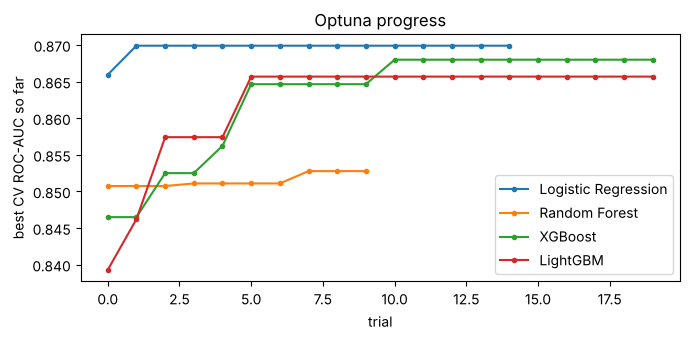

,C,colsample_bytree,learning_rate,max_depth,max_features,min_child_samples,min_child_weight,min_samples_leaf,n_estimators,num_leaves,reg_lambda,subsample
Logistic Regression,6.351221,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Forest,NaN,NaN,NaN,7,sqrt,NaN,NaN,10,300,NaN,NaN,NaN
XGBoost,NaN,0.701603,0.044534,2.0,NaN,NaN,12.0,NaN,350.0,NaN,0.105053,0.618884
LightGBM,NaN,0.561019,0.024906,NaN,NaN,72.0,NaN,NaN,350.0,7.0,0.431116,0.776061


In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, s in studies.items():
    ax.plot(np.maximum.accumulate([t.value for t in s.trials]), marker="o", ms=3, label=name)
ax.set_xlabel("trial"); ax.set_ylabel("best CV ROC-AUC so far"); ax.legend(); ax.set_title("Optuna progress")
plt.tight_layout(); plt.show()
pd.DataFrame({k: pd.Series(v) for k, v in best_params.items()}).T.round(4)

## 5. Validation: fresh out-of-fold predictions
Each tuned model is re-scored on new fold splits. The threshold that maximises F1 on these out-of-fold probabilities becomes that model's operating point.

In [8]:
def build_tuned(name, params):
    space, _ = SPACES[name]
    class Fixed:                                   # replay best params through the same constructor
        def __init__(self, p): self.p = p
        def suggest_float(self, n, *a, **k): return self.p[n]
        suggest_int = suggest_categorical = suggest_float
    est = space(Fixed(params))
    return build_pipeline(X_train, est, drop=LEAK_OR_ID)[0]

def best_f1_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.argmax(f1)])

models = {"Dummy (prior)": build_pipeline(X_train, DummyClassifier(strategy="prior"), drop=LEAK_OR_ID)[0]}
models.update({n: build_tuned(n, p) for n, p in best_params.items()})

val_rows, thresholds, oof = [], {}, {}
for name, pipe in models.items():
    p = cross_val_predict(pipe, X_train, y_train, cv=cv_val, method="predict_proba")[:, 1]
    fold_auc = [roc_auc_score(y_train.iloc[v], p[v]) for _, v in cv_val.split(X_train, y_train)]
    thr = best_f1_threshold(y_train, p) if name != "Dummy (prior)" else 0.5
    pred = (p >= thr).astype(int); oof[name], thresholds[name] = p, thr
    val_rows.append({"model": name, "val_ROC_AUC": roc_auc_score(y_train, p), "AUC_sd_folds": np.std(fold_auc),
                     "val_PR_AUC": average_precision_score(y_train, p), "threshold": thr,
                     "precision": precision_score(y_train, pred, zero_division=0),
                     "recall": recall_score(y_train, pred), "F1": f1_score(y_train, pred)})
val = pd.DataFrame(val_rows).set_index("model").sort_values("val_ROC_AUC", ascending=False)
val.round(3)

,val_ROC_AUC,AUC_sd_folds,val_PR_AUC,threshold,precision,recall,F1
model,,,,,,,
Logistic Regression,0.870,0.011,0.647,0.271,0.533,0.695,0.603
XGBoost,0.868,0.011,0.642,0.281,0.553,0.666,0.604
LightGBM,0.866,0.010,0.641,0.274,0.545,0.668,0.600
Random Forest,0.855,0.011,0.607,0.252,0.513,0.677,0.584
Dummy (prior),0.499,0.000,0.189,0.500,0.000,0.000,0.000


In [9]:
real = val.drop(index="Dummy (prior)")
champion = real["val_ROC_AUC"].idxmax()
top = real.loc[champion]
within = real[real["val_ROC_AUC"] >= top["val_ROC_AUC"] - top["AUC_sd_folds"]].index.tolist()
print("Champion on validation ROC-AUC:", champion)
print("Models within one fold-SD of the champion:", within)

Champion on validation ROC-AUC: Logistic Regression
Models within one fold-SD of the champion: ['Logistic Regression', 'XGBoost', 'LightGBM']


If several models sit within one fold standard deviation of each other, the gap is not meaningful. The table above makes that visible; prefer the simpler or more interpretable model among ties when stakes or audit needs favour it. Here the rule is kept mechanical (highest validation ROC-AUC) and the near-ties are reported.

## 6. One-time test evaluation, ROC curves, confusion matrices

In [10]:
test_rows, test_p, fitted = [], {}, {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train); fitted[name] = pipe
    p = pipe.predict_proba(X_test)[:, 1]; test_p[name] = p
    thr = thresholds[name]; pred = (p >= thr).astype(int)
    test_rows.append({"model": name, "test_ROC_AUC": roc_auc_score(y_test, p), "test_PR_AUC": average_precision_score(y_test, p),
                      "Brier": brier_score_loss(y_test, p), "precision": precision_score(y_test, pred, zero_division=0),
                      "recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred)})
test = pd.DataFrame(test_rows).set_index("model")
comparison = val[["val_ROC_AUC", "val_PR_AUC", "F1"]].rename(columns={"F1": "val_F1"}).join(
    test[["test_ROC_AUC", "test_PR_AUC", "precision", "recall", "F1", "Brier"]].rename(columns={"F1": "test_F1"}))
comparison.round(3)

,val_ROC_AUC,val_PR_AUC,val_F1,test_ROC_AUC,test_PR_AUC,precision,recall,test_F1,Brier
model,,,,,,,,,
Logistic Regression,0.870,0.647,0.603,0.867,0.632,0.519,0.715,0.602,0.104
XGBoost,0.868,0.642,0.604,0.863,0.628,0.513,0.666,0.579,0.105
LightGBM,0.866,0.641,0.600,0.861,0.625,0.513,0.672,0.582,0.105
Random Forest,0.855,0.607,0.584,0.850,0.598,0.488,0.675,0.567,0.114
Dummy (prior),0.499,0.189,0.000,0.500,0.189,0.000,0.000,0.000,0.153


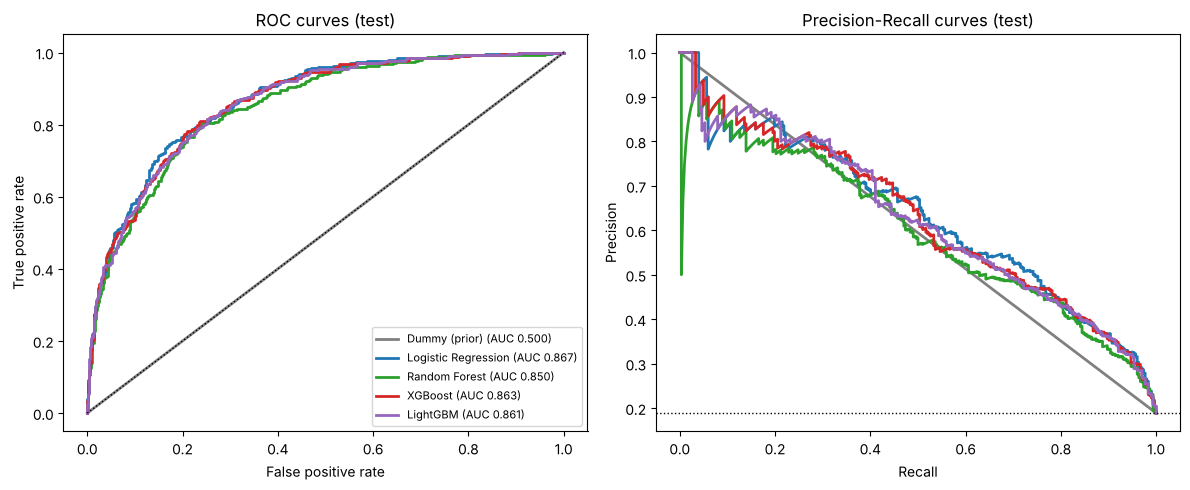

In [11]:
colors = dict(zip(models, ["grey", "tab:blue", "tab:green", "tab:red", "tab:purple"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, test_p[name]); axes[0].plot(fpr, tpr, color=colors[name], lw=2,
        label=f"{name} (AUC {roc_auc_score(y_test, test_p[name]):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, test_p[name]); axes[1].plot(rc, pr, color=colors[name], lw=2, label=name)
axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (test)")
axes[1].axhline(y_test.mean(), color="k", ls=":", lw=1); axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curves (test)")
axes[0].legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

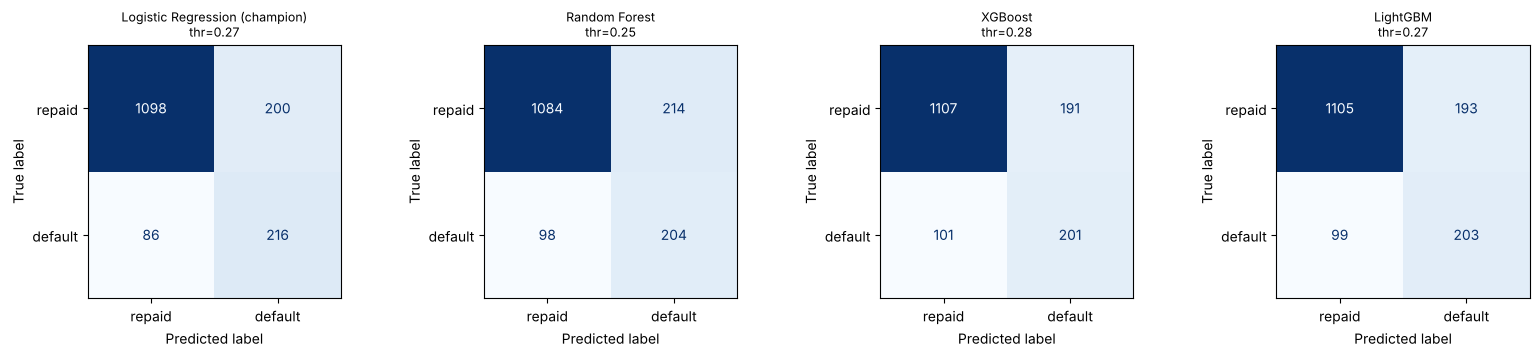

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, name in zip(axes, [n for n in models if n != "Dummy (prior)"]):
    pred = (test_p[name] >= thresholds[name]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["repaid", "default"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}" + (" (champion)" if name == champion else "") + f"\nthr={thresholds[name]:.2f}", fontsize=9)
plt.tight_layout(); plt.show()

**Reading the confusion matrices:** the threshold maximises F1, which weights false positives and false negatives equally. In a real lending or retention setting the costs differ, so pick the threshold from an explicit cost ratio (as in the problem-framing memo) rather than F1.

## 7. Serialize the champion

In [13]:
champion_pipe = fitted[champion]
joblib.dump(champion_pipe, "champion_model.joblib")
meta = {"champion": champion, "threshold": thresholds[champion], "best_params": best_params[champion],
        "validation": val.loc[champion].round(4).to_dict(), "test": test.loc[champion].round(4).to_dict(),
        "features_dropped_as_leak_or_id": LEAK_OR_ID, "seed": SEED,
        "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__, "xgboost": xgboost.__version__,
                     "lightgbm": lightgbm.__version__, "pandas": pd.__version__}}
json.dump(meta, open("champion_model_card.json", "w"), indent=2, default=float)

loaded = joblib.load("champion_model.joblib")
assert np.allclose(loaded.predict_proba(X_test)[:, 1], test_p[champion])
print("Saved champion_model.joblib and champion_model_card.json; reload check passed.")
print(json.dumps(meta, indent=2, default=float)[:900])

Saved champion_model.joblib and champion_model_card.json; reload check passed.
{
  "champion": "Logistic Regression",
  "threshold": 0.27128006069602256,
  "best_params": {
    "C": 6.351221010640703
  },
  "validation": {
    "val_ROC_AUC": 0.8703,
    "AUC_sd_folds": 0.0112,
    "val_PR_AUC": 0.6474,
    "threshold": 0.2713,
    "precision": 0.533,
    "recall": 0.6954,
    "F1": 0.6034
  },
  "test": {
    "test_ROC_AUC": 0.867,
    "test_PR_AUC": 0.6323,
    "Brier": 0.1037,
    "precision": 0.5192,
    "recall": 0.7152,
    "F1": 0.6017
  },
  "features_dropped_as_leak_or_id": [
    "customer_id",
    "collections_status_30d_after"
  ],
  "seed": 42,
  "versions": {
    "python": "3.12.3",
    "sklearn": "1.9.1",
    "xgboost": "3.4.1",
    "lightgbm": "4.7.0",
    "pandas": "3.0.6"
  }
}


### Notes and limits
- **Loading the file:** `CorrelationFilter` and `build_pipeline` are defined in this notebook, so run (or import) section 2 before `joblib.load`, and use the same library versions listed in the model card.
- **Selection bias:** tuning scores are optimistic by construction; the validation table uses fresh folds, and the test column is the unbiased estimate.
- **Synthetic data:** metrics demonstrate the workflow, not real-world performance. Re-run on real data, with a time-based split and calibration check, before any decision.